# Marine gravity currents on a passive margin

Rivers deliver most of their load to the coast, where goSPL's clinoform scheme builds a prograding wedge of topsets and foresets. Part of the load, however, does not settle there: during floods, sediment-laden river water plunges as **hyperpycnal flows**, and failures on the delta front generate **turbidity currents**. These gravity currents cross the shelf and the slope and build coarse-grained bodies at the foot of the slope and finer lobes on the basin floor.

goSPL's optional `gravity:` block adds this second pathway. The currents are not resolved as flows (a turbidity-current model needs time steps of seconds); a fraction of the river load is instead **routed down the seafloor** and deposits gradually over a **run-out length**:

$$\left(I - W^T \mathrm{diag}(1 - \Lambda)\right) q = s, \qquad D_i = \Lambda_i q_i, \qquad \Lambda_i = \left(1 - e^{-\ell_i / L}\right) T_d(d_i)\, T_S(S_i)$$

with $s$ the diverted supply, $W$ the receiver weights of the seafloor network, $q$ the flux, $\ell_i$ the cell size, $L$ the run-out length, and $T_d$, $T_S$ smooth tapers that make the currents bypass the shelf (water shallower than `bypass_depth`) and the steep foresets (`bypass_slope`). The system is linear, solved once per step and grain fraction, and conserves volume exactly (supplied = deposited + exported). The equations and every parameter are described in the goSPL technical and user guides (*Gravity currents*).

This example runs the margin of the [`dual_lithology`](../dual_lithology) example (200 x 100 km, 615 m cells, coarse and fine sediment, falling and oscillating sea level, flexure) for 250 kyr, **with and without** gravity currents, and compares the surface, the deposits and the stratigraphy.

## Running the simulations

The mesh and the sea-level curve are in `data/` (the same files as in `dual_lithology`). The example needs a goSPL with the gravity-current module (the `environment.yml` of this branch builds it).

```bash
./run_all.sh     # the three runs (4 ranks each, about 2 minutes each side by side)
# or one run:
mpirun -np 4 gospl -i input-gravity.yml --summary summary_gravity.jsonl
```

`input-gravity.yml` differs from `input-nogravity.yml` only by its `gravity:` block:

```yaml
gravity:
    fraction: 0.3         # 30 % of the river load reaching the sea becomes gravity currents
    coarse_factor: 0.3    # ... but only 0.3 x that for the coarse load (mostly suspended load)
    runout: 1.e4          # coarse run-out length (m)
    runout_fine: 2.e4     # fine run-out length (m)
    bypass_slope: 0.01    # less deposition on the foresets (bypass_depth: 50 m by default)
    receivers: 2          # coarse network: concentrated pathways (belts)
    flow_exp: 4.
    receivers_fine: 6     # fine network: spreading (lobes)
    flow_exp_fine: 1.
    network_smooth: 3     # smoothing passes of the routing surface
    slope_smooth: 3       # smoothing passes of the slope used by the tapers
    deposit_spread: 1500. # lateral spreading of each step's deposit (m)
```

`input-failure.yml` adds the slope-failure trigger to `input-gravity.yml` (see the last section). Run side by side with 4 ranks each on a laptop, the 50 steps take about 2 minutes per run (`log_*.txt`).

In [1]:
import matplotlib.pyplot as plt
%matplotlib inline

from scripts import gravity

STEP = gravity.last_step("sim_gravity")   # 25: 250 kyr (outputs every 10 kyr)
print("output step", STEP)

output step 25


## Gravity budget

With `--summary`, every step's record carries the gravity budget: the volume supplied to the currents, the volume they deposit and the volume they export through the open boundaries (and the volume eroded, when slope erosion is on). The budget closes to the solver tolerance.

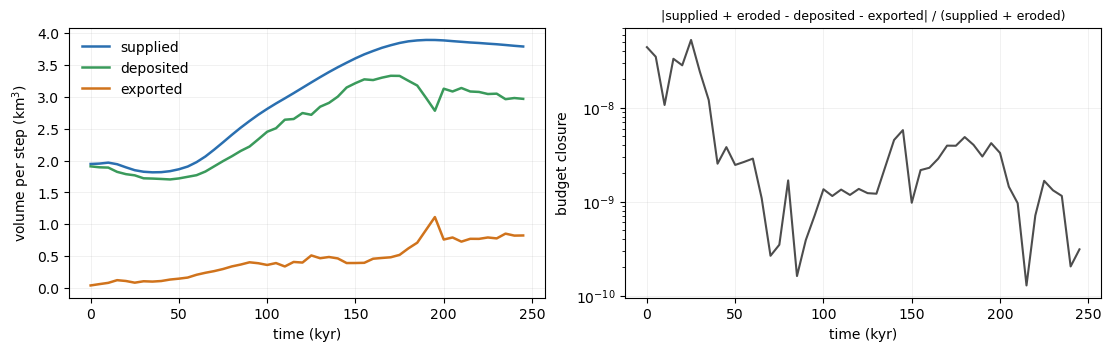

In [2]:
fig = gravity.budget("summary_gravity.jsonl")
plt.show()

## Map views

Top: the margin without gravity currents. The clinoform wedge ends at the foot of the slope and the basin floor receives nothing. Bottom: with gravity currents, sediment bypasses the shelf and the foresets and spreads over the basin floor (middle panel). The coarse load follows the concentrated network and stays nearer the slope base; the fine load, on its spreading network with a longer run-out, goes further. With `coarse_factor: 0.3` the gravity deposits are mixed (fine fraction about 0.4 to 0.6 near the slope base), get finer basinward, and keep finer streaks between the main pathways (right panel).

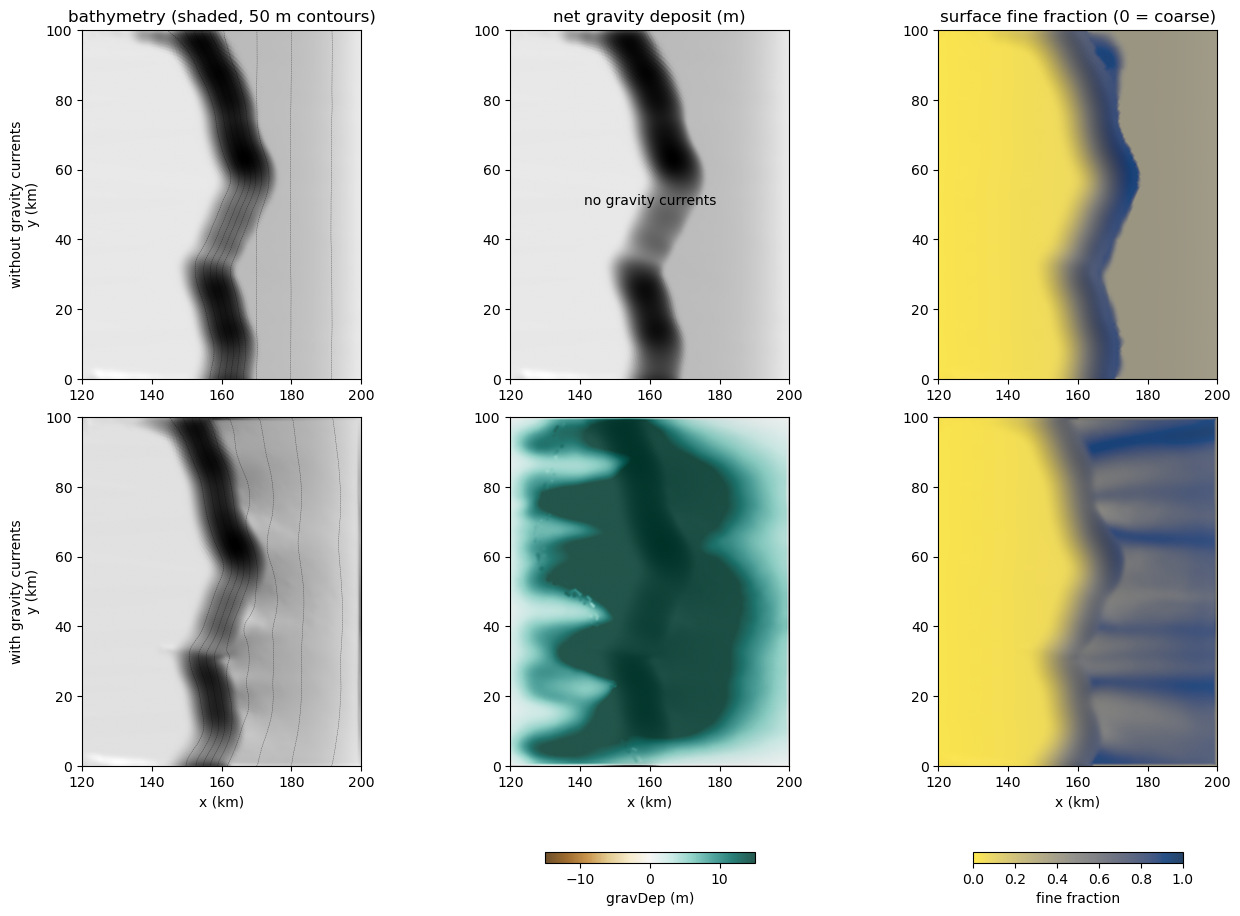

In [3]:
fig = gravity.maps(STEP)
plt.show()

## Strike sections

Profiles along the margin (along $y$) every 10 km from the shelf (130 km) to the basin floor (190 km). Left: elevation (dashed: initial surface). Right: cumulative deposit (solid) and flexural displacement (dotted). The elevation of the basin floor drops by 30 to 50 m in both runs: that is the flexural subsidence under the sediment load, not erosion. Beyond the toe of the clinoforms (about 175 km) only the run with gravity currents deposits.

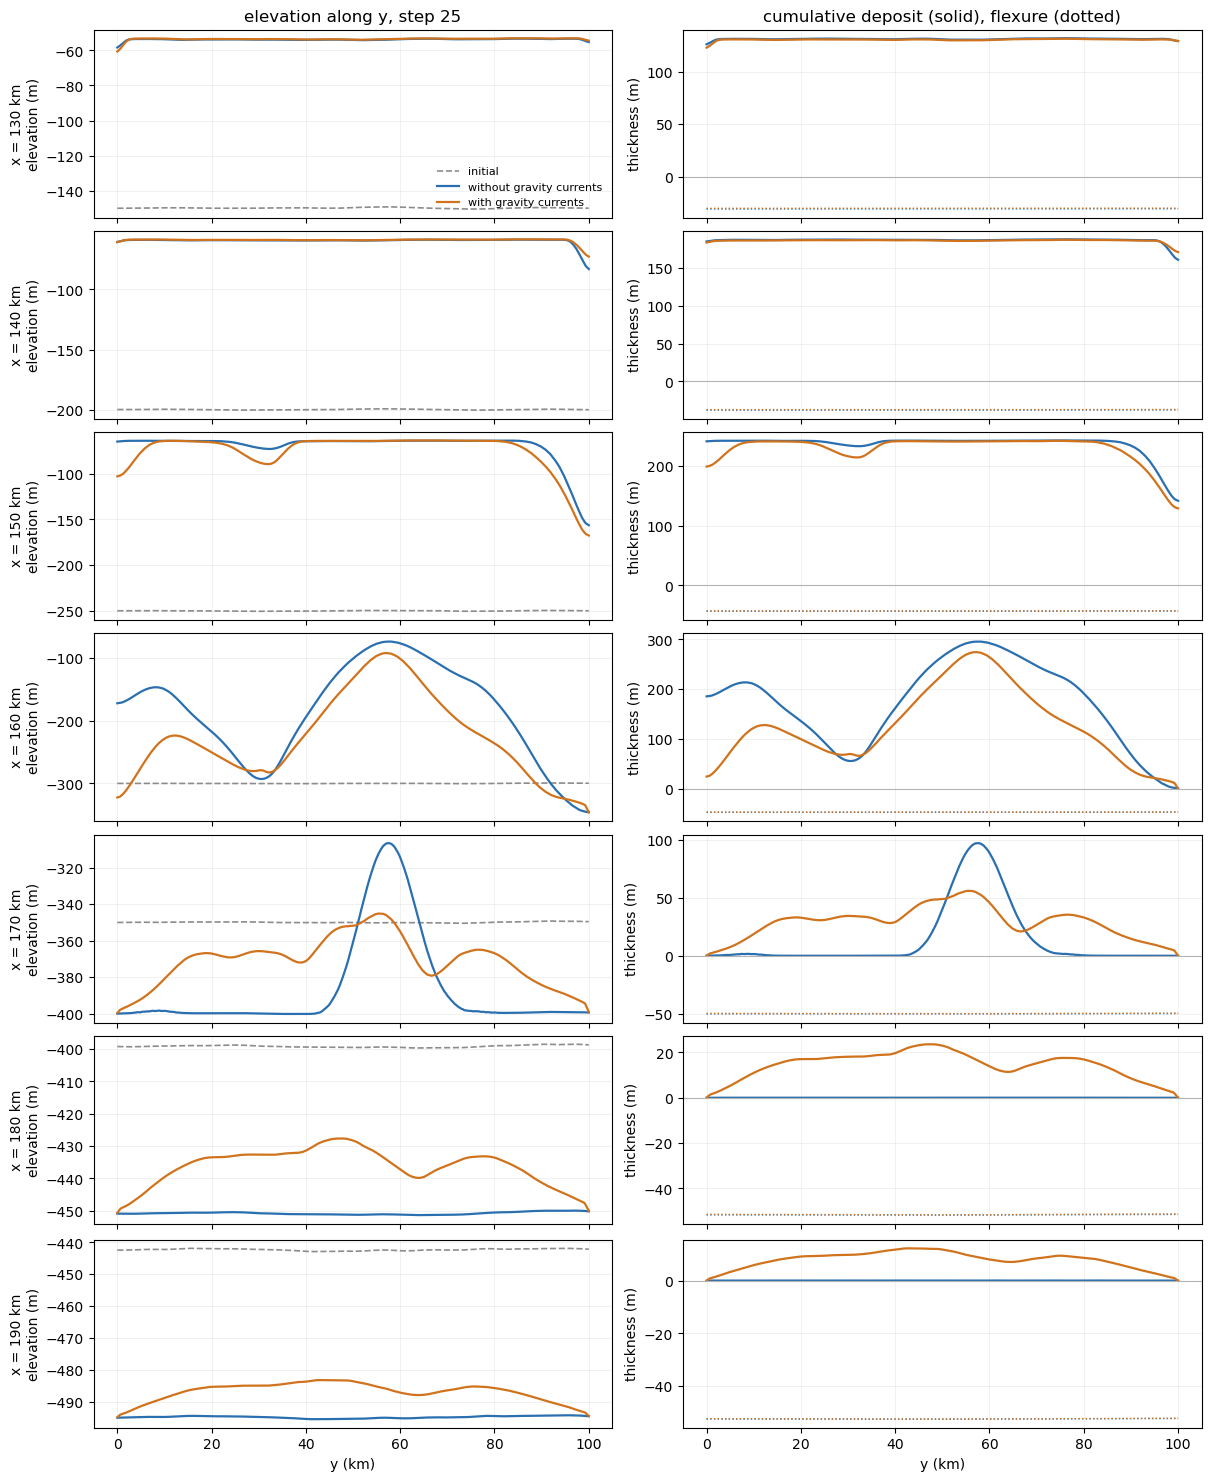

In [4]:
fig = gravity.strike_sections(STEP)
plt.show()

## Stratigraphy

Dip sections (along $x$) at three positions along the margin, drawn with goSPL's `gospl.analyse.stratasection.cross_section` (also available as the `gospl-section` command): each layer is a filled band between its present-day interfaces, with the surface (thick black), the basement (grey) and the sea level (blue). First coloured by the fine fraction of each layer. Without gravity currents the clinoforms have coarse topsets and fine toesets and stop at 165 to 175 km. With them, a band of bottomset layers continues from the slope toe to the basin floor at 200 km: mixed near the toe and finer downdip.

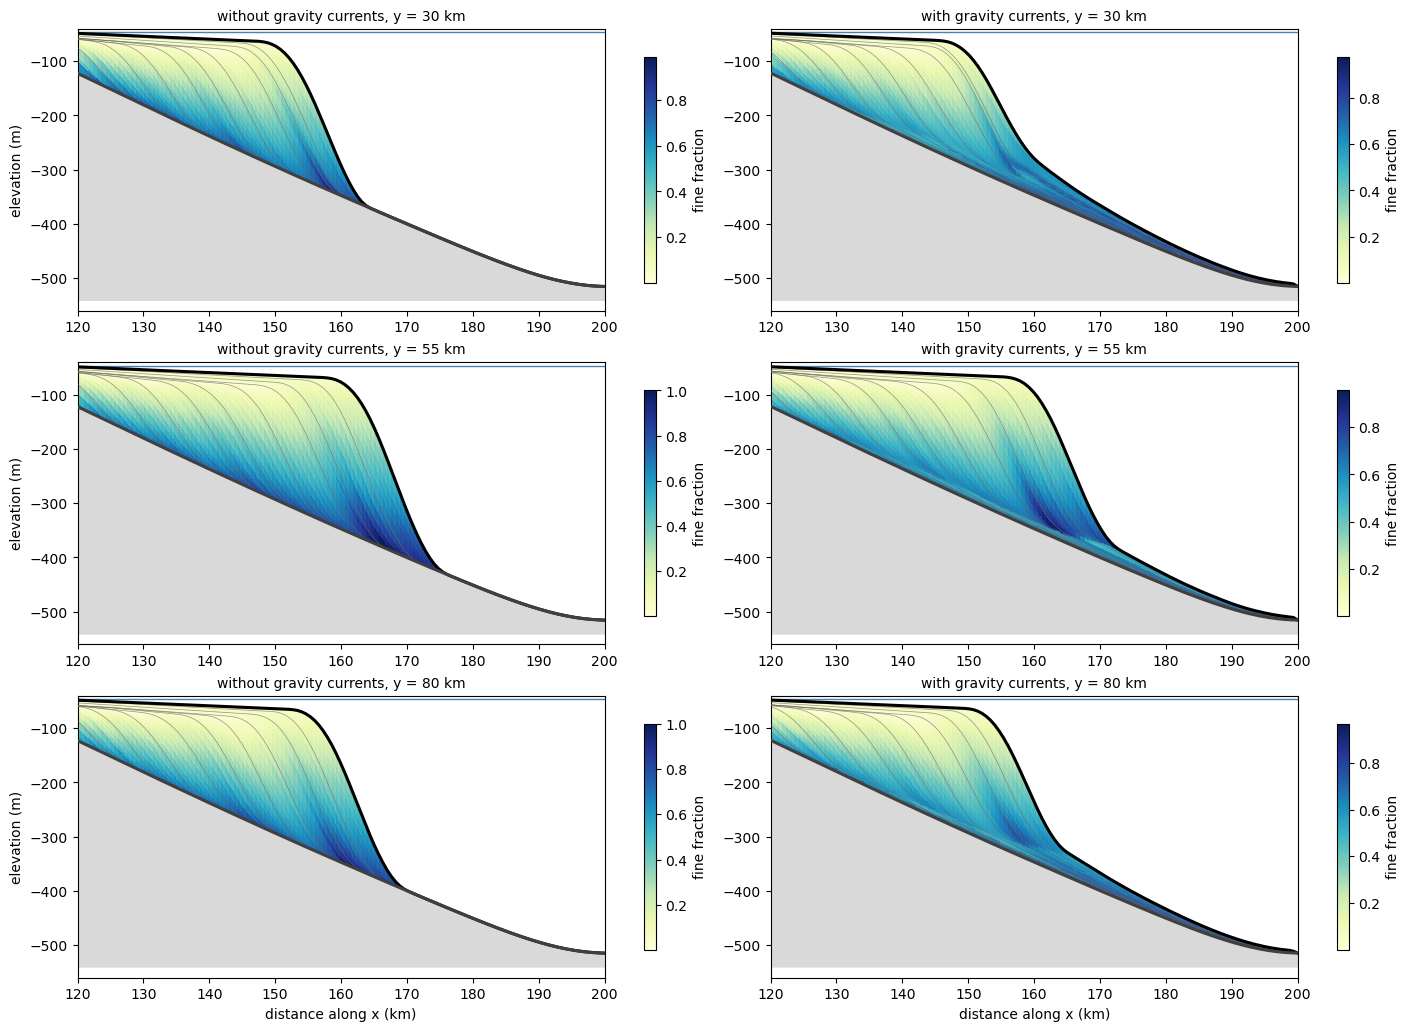

In [5]:
fig = gravity.dip_sections(STEP, color_by="lithology")
plt.show()

The same sections coloured by **depositional facies**, set by the water depth at the time each layer was deposited (sea level minus `stratZ`): fluvial or deltaic plain above sea level, then shoreface, distal offshore, upper slope and lower slope with depth (bin edges 0, 20, 50 and 75 m below sea level, tunable in `cross_section`). The gravity bottomsets are all lower-slope facies: they formed in more than 75 m of water, beyond the foresets.

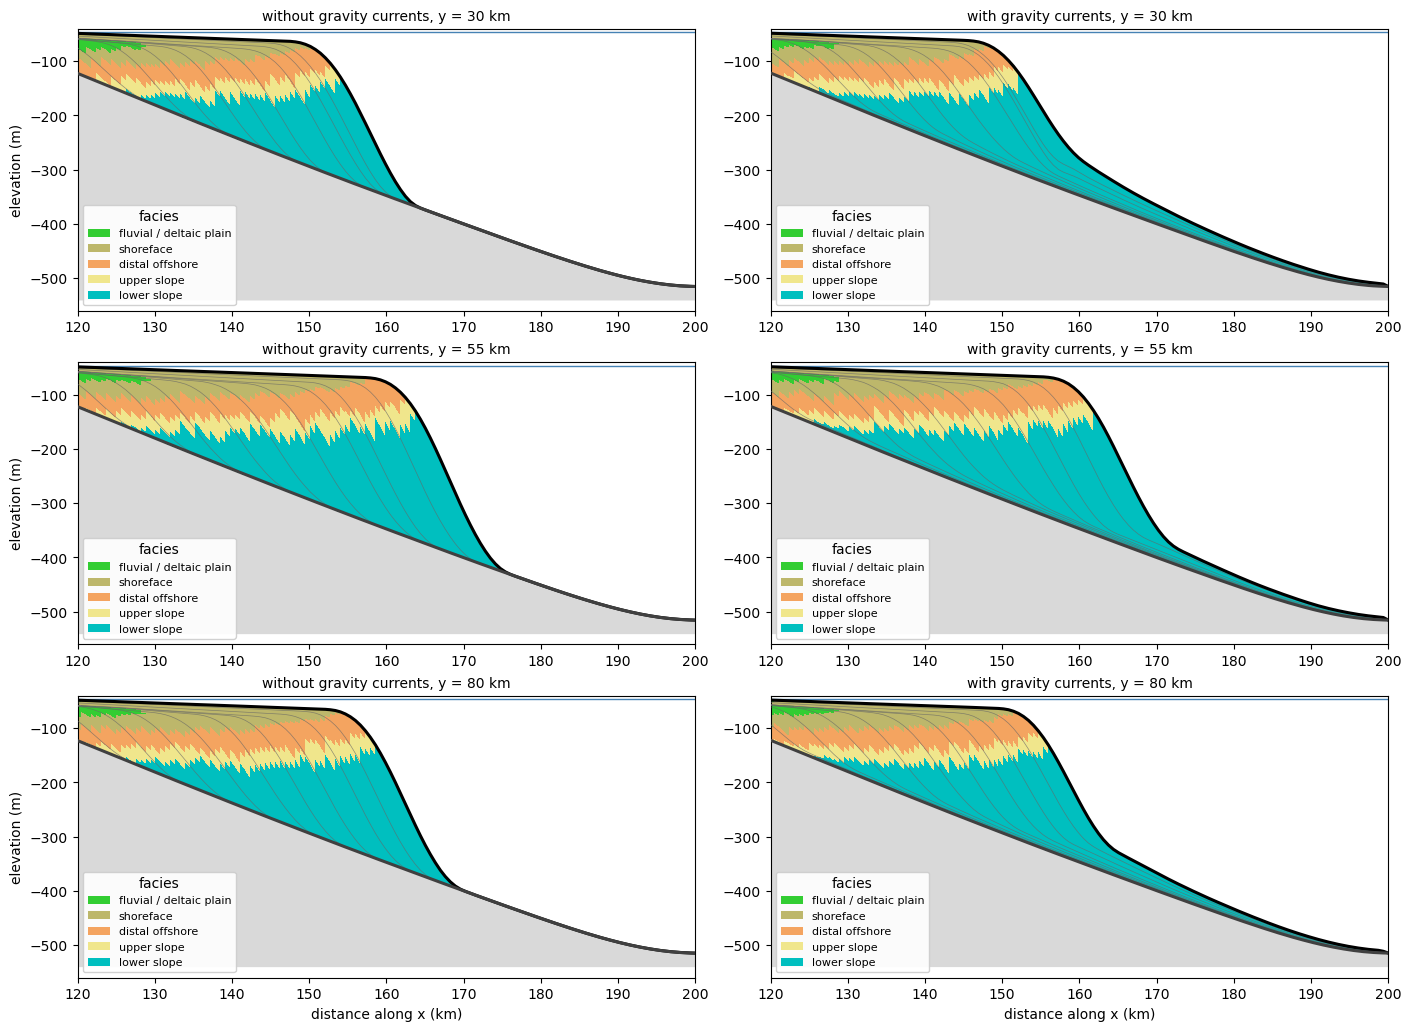

In [6]:
fig = gravity.dip_sections(STEP, color_by="facies")
plt.show()

## Slope failure

`input-failure.yml` adds goSPL's **slope-failure trigger** to the run with gravity currents:

```yaml
    failure_slope: 0.02   # sediment deposited during the run fails where the seafloor is steeper
    max_failure: 10.      # at most 10 m per cell and step
```

Wherever the (smoothed) seafloor below the bypass depth is steeper than 0.02, the sediment deposited during the run fails down to that gradient, $\Delta z = \min\left((S - S_f)\,\ell/2,\; 10\ \mathrm{m},\; D\right)$ ($\ell$ the cell size, $D$ the sediment deposited so far, so bedrock never fails), and joins the gravity currents with its composition. The failing cell receives no gravity deposit in that step. The gradient 0.02 is chosen from this margin's foresets, which reach about 0.03.

The budget now reports the failed volume. Failures start after about 130 kyr, when the falling sea level has steepened the foresets, and grow to about 1 km³ per step, a quarter of the river supply to the currents; the budget still closes to the solver tolerance.

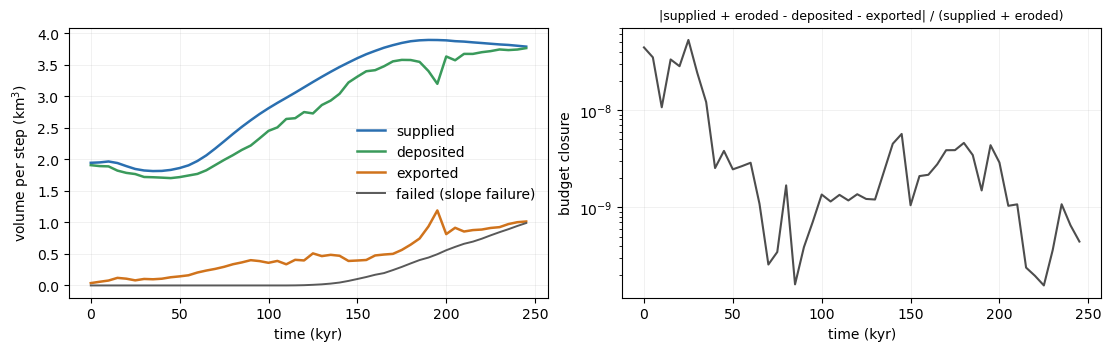

In [7]:
fig = gravity.budget("summary_failure.jsonl")
plt.show()

Failures concentrate in a few scars on the foresets (brown in the middle panel, where more sediment failed than the currents deposited), and the remobilised sediment spreads over the basin floor, whose surface becomes more mixed (right panel). Failures add a little cell-scale roughness to the deposit.

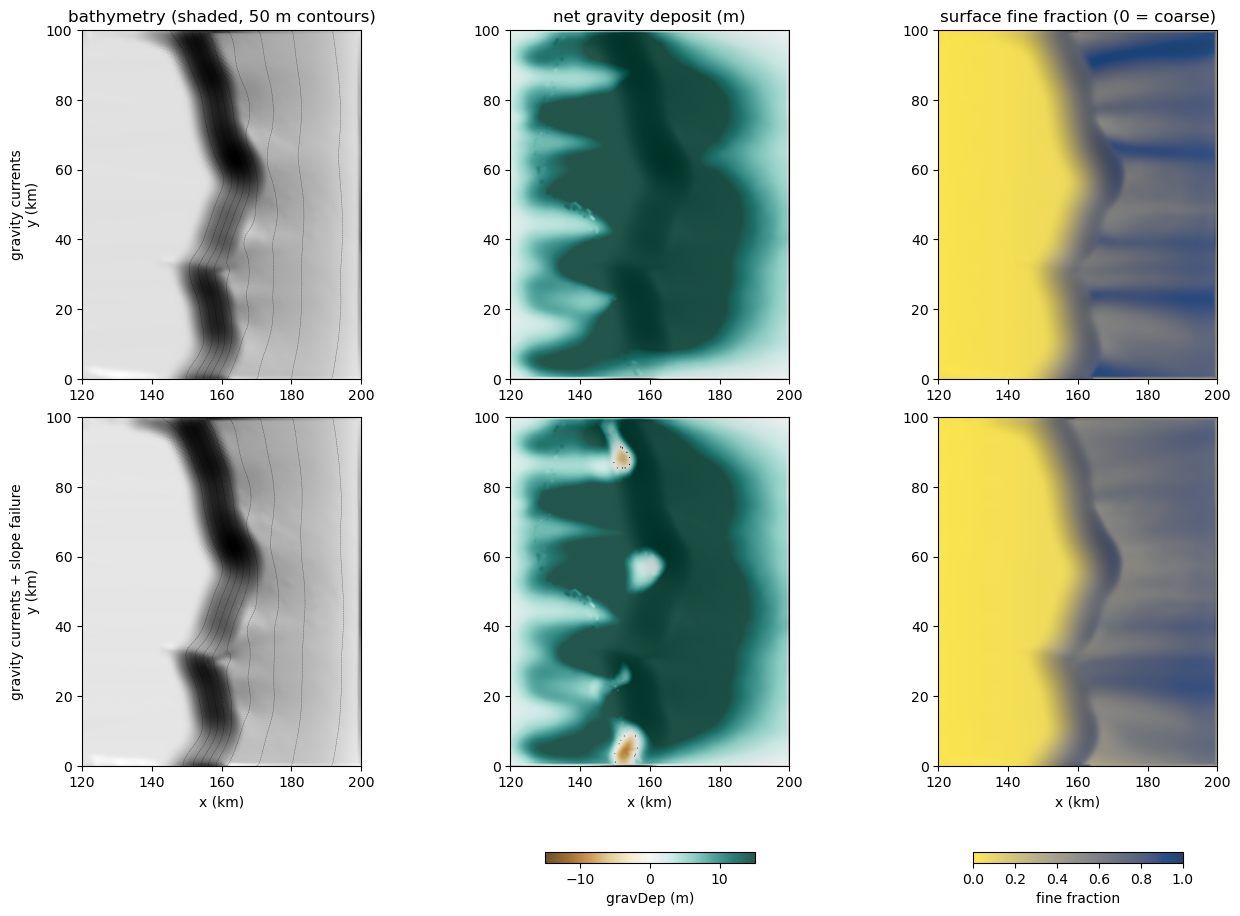

In [8]:
fig = gravity.maps(STEP, runs=gravity.FAILURE)
plt.show()

Dip sections through the three scars (y = 5, 58 and 88 km). The differences are small at this scale, a few metres removed from a pile about 300 m thick: where sediment failed the foresets are slightly gentler, and the material reappears in the bottomsets.

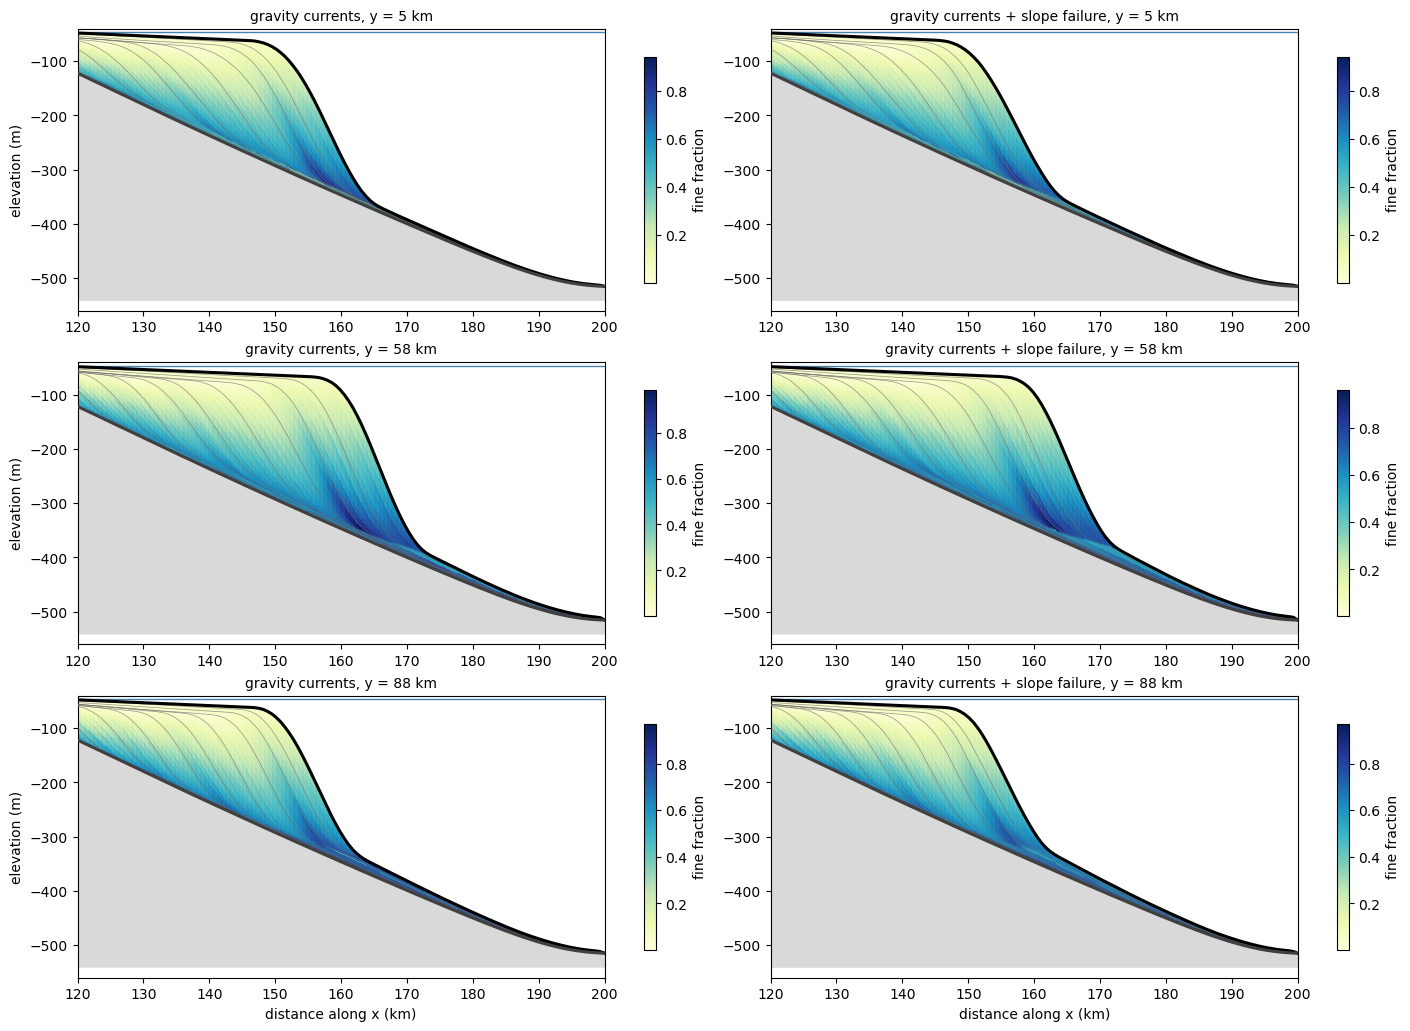

In [9]:
fig = gravity.dip_sections(STEP, ys=(5e3, 58e3, 88e3), runs=gravity.FAILURE)
plt.show()

## Things to try

- Replace `fraction: 0.3` by a `flood:` block (`sigma: 2.` for flashy rivers) to compute the fraction from floods above the hyperpycnal threshold.
- Set `coarse_factor: 1.`: as much coarse as fine is diverted and thick coarse lobes build at the foot of the slope.
- Set `deposit_spread: 0` (spreading is on by default, over two cell sizes): the concentrated coarse network then builds ridges one cell wide.
- Lengthen the run-outs to move the deposits further into the basin.
- Change `failure_slope` (0.015 to 0.03) and `max_failure` in `input-failure.yml`.

Slope erosion by the currents (`erosion_length`) is left off: it is an expert option for meshes of 200 m cells or finer, and at this resolution (615 m cells, 5 kyr steps) it only roughens the toe of the slope. See the goSPL user guide (*Marine gravity currents*) for the cautions.